# Final model: CNN-GRU with physics head, dT/dt and cumulative-energy channels

**Goal of this notebook:** train the final model with the improvements that the experiments (`3_improvements.ipynb`) showed were worth it, choose it on the validation split, and evaluate it **once** on the test split.

The reasons behind each choice (and the options I dropped) are in `3_improvements.ipynb`, section 10.

**Assessment constraints respected**
- The model input is only **T_int(t) and U(t)** (480 one-minute steps), loaded and rounded exactly as in the assessment's loading code. The dT/dt and cumulative-energy channels are computed from them **inside the model**, so the model's interface is (T, U) -> 6 targets.
- The outputs are the six indicators (HLC, HLC_mit, HLC_ext, tau_b, tau_n, tau_inf) in W/K and hours. The sum rule HLC = HLC_mit + HLC_ext holds exactly.
- Everything is implemented in PyTorch, with the code in `src/coenergy/` and the environment in `uv`.

**Protocol**
1. Train one model per seed (same split, same scalers, same `TrainConfig`; only the initial weights and the batch order change).
2. **Validation:** compare each seed, the 3-seed ensemble, and the first-iteration model. The final model is chosen here.
3. **Test (used once):** per-seed mean ± std, the ensemble, and the comparison with the baselines.
4. Check the physics rules, the predictions against the truth, and the errors by subset.
5. Map the error against the settings of the heating signal (PRBS parameters), to see which measurement protocol gives the most accurate predictions.

## 1. Setup and data

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch

from coenergy.data import load_solicitation, load_splits
from coenergy.experiments import heating_pattern
from coenergy.metrics import constraint_violations, metrics_by_group, per_target_metrics
from coenergy.models import build_baseline_cnn, build_cnn_gru, derivative_std
from coenergy.preprocessing import Scalers
from coenergy.training import TrainConfig, predict, train_model

SEED = 67  # seed of the split and scalers (EDA)
PROJECT_ROOT = Path.cwd().parent
DATA_DIR = PROJECT_ROOT / 'data' / 'quentin_house'
SPLIT_PATH = PROJECT_ROOT / 'data' / 'splits' / f'split_70_15_15_seed{SEED}.pt'
SCALER_PATH = PROJECT_ROOT / 'data' / 'splits' / f'scalers_seed{SEED}.pt'
CKPT_DIR = PROJECT_ROOT / 'models'
FIG_DIR = PROJECT_ROOT / 'reports' / 'figures'
RESULTS_DIR = PROJECT_ROOT / 'reports' / 'final'
for d in (CKPT_DIR, FIG_DIR, RESULTS_DIR):
    d.mkdir(parents=True, exist_ok=True)
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

# Final configuration
SEEDS = (0, 1, 2)
EXTRA = ('dT', 'energy')
RETRAIN = False  # False: load the saved checkpoints if they exist

plt.rcParams.update({'figure.dpi': 110, 'axes.grid': True, 'grid.alpha': 0.3})
print(f'torch {torch.__version__} | device: {DEVICE}')

torch 2.11.0+cu128 | device: cuda


In [2]:
scalers = Scalers.load(SCALER_PATH)
assert scalers.seed == SEED
data = load_splits(DATA_DIR, SPLIT_PATH, scalers)  # same rounding as the assessment's loading code
train, val, test = data['train'], data['val'], data['test']
labels = scalers.target_labels

dT_std = derivative_std(train.x)
y_train_phys = scalers.denorm_targets(train.y)
y_val = scalers.denorm_targets(val.y)
y_test = scalers.denorm_targets(test.y)

cfg = TrainConfig()  # 20 epochs, batch 256, AdamW lr 2e-3, one-cycle schedule, best epoch kept
print(f'train {len(train):,} | val {len(val):,} | test {len(test):,}')
cfg

train 700,000 | val 150,000 | test 150,000


TrainConfig(epochs=20, batch_size=256, lr=0.002, weight_decay=0.0001, patience=4, eval_batch_size=4096, max_train=None, data_on_device=True, seed=67)

## 2. Train one model per seed

Each seed builds a fresh model (`torch.manual_seed(seed)` before building it) and trains it with `cfg.seed = seed` for the batch order. The best weights by validation loss and the training history are saved in `models/final_s{seed}.pt` and `final_s{seed}_history.csv`. With `RETRAIN = False`, existing checkpoints are loaded instead of retrained.

In [3]:
def make_final():
    return build_cnn_gru('physics', dT_std, scalers.tgt_mean, scalers.tgt_std,
                         y_train_phys=y_train_phys, extra=EXTRA)


models, histories = {}, {}
for seed in SEEDS:
    ckpt, hist_path = CKPT_DIR / f'final_s{seed}.pt', CKPT_DIR / f'final_s{seed}_history.csv'
    torch.manual_seed(seed)
    model = make_final()
    if RETRAIN or not ckpt.exists() or not hist_path.exists():
        print(f'--- training seed {seed} ---')
        cfg_seed = TrainConfig(seed=seed)
        history = train_model(model, train, val, scalers, cfg_seed, device=DEVICE, checkpoint_path=ckpt)
        history.to_csv(hist_path)
    else:
        model.load_state_dict(torch.load(ckpt, weights_only=False)['state_dict'])
        model.to(DEVICE)
        history = pd.read_csv(hist_path, index_col='epoch')
    models[seed], histories[seed] = model, history

print(f"parameters per model: {sum(p.numel() for p in models[SEEDS[0]].parameters()):,}")
pd.DataFrame({f'seed {s}': {'best epoch': int(h['val_loss'].idxmin()), 'best val loss': h['val_loss'].min(),
                            'final train loss': h['train_loss'].iloc[-1]} for s, h in histories.items()}).round(4)

parameters per model: 246,533


,seed 0,seed 1,seed 2
best epoch,19.0000,19.0000,19.0000
best val loss,0.7175,0.7183,0.7194
final train loss,0.7030,0.7010,0.6994


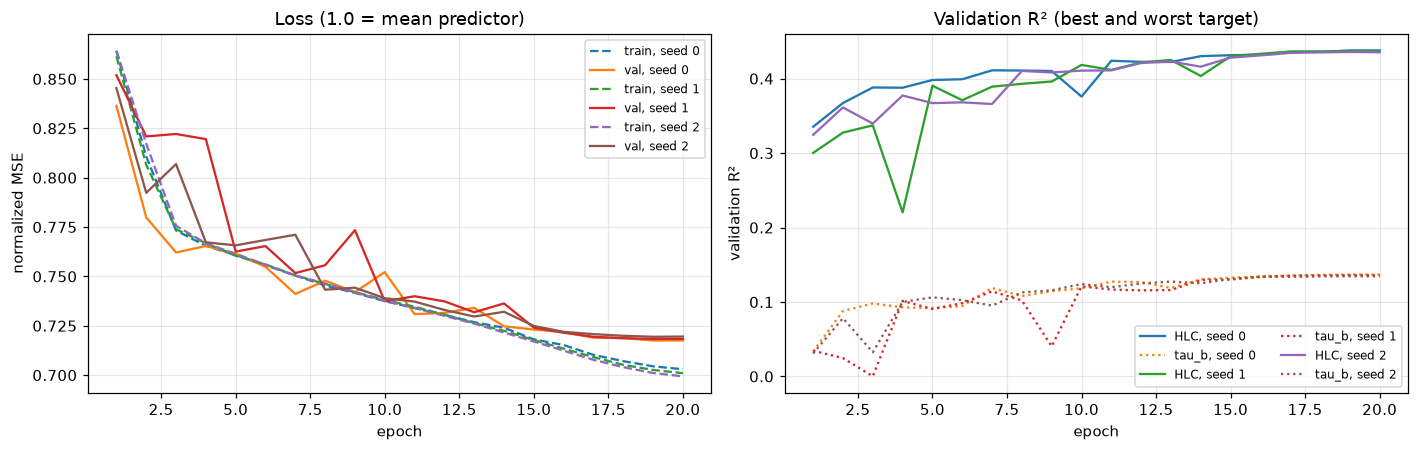

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))
for s, h in histories.items():
    axes[0].plot(h.index, h['train_loss'], ls='--', label=f'train, seed {s}')
    axes[0].plot(h.index, h['val_loss'], label=f'val, seed {s}')
    axes[1].plot(h.index, h['R2_HLC'], label=f'HLC, seed {s}')
    axes[1].plot(h.index, h['R2_tau_b'], ls=':', label=f'tau_b, seed {s}')
axes[0].set_xlabel('epoch'); axes[0].set_ylabel('normalized MSE'); axes[0].set_title('Loss (1.0 = mean predictor)')
axes[1].set_xlabel('epoch'); axes[1].set_ylabel('validation R²'); axes[1].set_title('Validation R² (best and worst target)')
axes[0].legend(fontsize=8); axes[1].legend(fontsize=8, ncol=2)
fig.tight_layout()
fig.savefig(FIG_DIR / 'final_training_curves.png', dpi=150)
plt.show()

**Observations (training)**
- **All three seeds train the same way.** Best epoch 19 for every seed, best validation loss 0.7175, 0.7183 and 0.7194. The spread between seeds (about 0.001) is tiny.
- **No overfitting.** At epoch 20, train loss is about 0.70 and validation 0.72 for every seed. The gap only opens in the last epochs, when the learning rate is almost 0.
- **Same behaviour as the first iteration:** validation loss is noisy while the learning rate is high (first half), then decreases smoothly and levels off. The model with the energy channel has 246,533 parameters (448 more than before, from the extra input channel).

## 3. Model selection on the validation split

The final prediction is the **average of the 3 seeds** (an ensemble). It is compared on validation with each seed alone and with the first-iteration model (`models/cnn_gru_physics.pt`: physics head, dT/dt only, one run). The test split is still unused here.

In [5]:
def ensemble_predict(models, x):
    # Average of the physics-head predictions: still positive, sum rule and tau order preserved
    return torch.stack([predict(m, x) for m in models.values()]).mean(dim=0)


first = build_cnn_gru('physics', dT_std, scalers.tgt_mean, scalers.tgt_std, y_train_phys=y_train_phys)
first.load_state_dict(torch.load(CKPT_DIR / 'cnn_gru_physics.pt', weights_only=False)['state_dict'])
first.to(DEVICE)

val_preds = {f'seed {s}': predict(m, val.x) for s, m in models.items()}
val_preds['ensemble (3 seeds)'] = torch.stack([val_preds[f'seed {s}'] for s in SEEDS]).mean(dim=0)
val_preds['first iteration'] = predict(first, val.x)

val_r2 = pd.DataFrame({name: per_target_metrics(p, y_val, labels)['R2'] for name, p in val_preds.items()})
val_r2.loc['mean of 6 targets'] = val_r2.mean()
val_r2.round(4)

,seed 0,seed 1,seed 2,ensemble (3 seeds),first iteration
HLC,0.4378,0.4371,0.4358,0.4406,0.4370
HLC_mit,0.2801,0.2797,0.2788,0.2822,0.2792
HLC_ext,0.4705,0.4696,0.4690,0.4758,0.4699
tau_b,0.1370,0.1360,0.1346,0.1396,0.1368
tau_n,0.2638,0.2629,0.2617,0.2669,0.2632
tau_inf,0.1053,0.1043,0.1032,0.1071,0.1050
mean of 6 targets,0.2824,0.2816,0.2805,0.2854,0.2818


**Observations (validation)**
- **Each seed alone is not measurably better than the first-iteration model.** HLC R² is 0.436-0.438 for the three seeds against 0.437 for the first iteration, and the mean over the six targets is 0.281-0.282 against 0.282. The first-iteration score sits inside the spread of the three seeds, and that spread (about 0.002) is only luck from the random initial weights. So on the full data, **the cumulative-energy channel brings no measurable gain**: the +0.003 seen on the 200k subset in `3_improvements.ipynb` does not carry over. With 700k scenarios and 20 epochs, the network probably learns this information from U(t) on its own.
- **The ensemble is better than every single model on every target:** HLC 0.441, HLC_ext 0.476, tau_b 0.140, mean of the six targets 0.285, about +0.003 over the best seed. That is 2 to 3 times the seed spread, so it is a real gain. Each seed makes slightly different errors, and averaging cancels part of them.
- **Decision:** the final model is the **3-seed ensemble**: the three models predict, and the six outputs are averaged. The energy channel stays because it costs nothing and does not hurt, but the gain comes from the averaging. An ensemble of three first-iteration models would most likely give the same result.

## 4. Final evaluation on the test split (used once)

Three views:
1. **Each seed alone**, summarized as mean ± std: how much the result depends on the random seed.
2. **The ensemble**: the final model.
3. **Comparison** with the mean predictor, the baseline CNN and the first-iteration CNN-GRU (`2_modeling.ipynb` checkpoints), on the same test split.

In [6]:
test_seed = {s: per_target_metrics(predict(m, test.x), y_test, labels) for s, m in models.items()}
pred_final = ensemble_predict(models, test.x)
metrics_final = per_target_metrics(pred_final, y_test, labels)

per_seed = pd.concat({f'seed {s}': m for s, m in test_seed.items()})
seed_summary = pd.DataFrame({
    'R2 mean ± std (3 seeds)': [f"{per_seed.xs(l, level=1)['R2'].mean():.3f} ± {per_seed.xs(l, level=1)['R2'].std():.3f}" for l in labels],
    'MAE mean ± std (3 seeds)': [f"{per_seed.xs(l, level=1)['MAE'].mean():.2f} ± {per_seed.xs(l, level=1)['MAE'].std():.2f}" for l in labels],
    'ensemble R2': metrics_final['R2'].round(3).values,
    'ensemble MAE': metrics_final['MAE'].round(2).values,
}, index=labels)
seed_summary

,R2 mean ± std (3 seeds),MAE mean ± std (3 seeds),ensemble R2,ensemble MAE
HLC,0.436 ± 0.000,18.79 ± 0.01,0.440,18.730000
HLC_mit,0.279 ± 0.000,17.92 ± 0.01,0.282,17.889999
HLC_ext,0.470 ± 0.001,9.96 ± 0.01,0.476,9.900000
tau_b,0.136 ± 0.001,7.40 ± 0.00,0.140,7.380000
tau_n,0.265 ± 0.001,1.36 ± 0.00,0.269,1.350000
tau_inf,0.106 ± 0.001,5.59 ± 0.00,0.109,5.580000


In [7]:
# Final model: all metrics (W/K for the HLC family, hours for the time constants)
metrics_final.to_csv(RESULTS_DIR / 'final_test_metrics.csv')
metrics_final.round(3)

,MAE,RMSE,P95_abs,rel_MAE_%,R2
HLC,18.731001,23.468,46.030998,8.198,0.440
HLC_mit,17.891001,22.277,43.542000,15.723,0.282
HLC_ext,9.900000,12.366,24.132999,9.056,0.476
tau_b,7.381000,9.394,18.086000,15.113,0.140
tau_n,1.355000,1.725,3.336000,12.372,0.269
tau_inf,5.579000,7.136,13.669000,18.513,0.109


In [8]:
baseline = build_baseline_cnn(scalers.tgt_mean, scalers.tgt_std)
baseline.load_state_dict(torch.load(CKPT_DIR / 'baseline_cnn.pt', weights_only=False)['state_dict'])
baseline.to(DEVICE)

test_preds = {
    'mean predictor': scalers.tgt_mean.expand(len(test), -1).clone(),
    'baseline CNN': predict(baseline, test.x),
    'first iteration (CNN-GRU)': predict(first, test.x),
    'final (ensemble)': pred_final,
}
test_metrics = {name: per_target_metrics(p, y_test, labels) for name, p in test_preds.items()}
comparison_r2 = pd.DataFrame({n: m['R2'] for n, m in test_metrics.items()})
comparison_mae = pd.DataFrame({n: m['MAE'] for n, m in test_metrics.items()})
comparison_p95 = pd.DataFrame({n: m['P95_abs'] for n, m in test_metrics.items()})
comparison_r2.to_csv(RESULTS_DIR / 'comparison_test_r2.csv')
print('Test R2'); display(comparison_r2.round(3))
print('Test MAE (W/K or h)'); display(comparison_mae.round(2))
print('Test P95 absolute error (W/K or h)'); display(comparison_p95.round(2))

Test R2


,mean predictor,baseline CNN,first iteration (CNN-GRU),final (ensemble)
HLC,0.0,0.368,0.436,0.440
HLC_mit,-0.0,0.242,0.279,0.282
HLC_ext,-0.0,0.246,0.470,0.476
tau_b,-0.0,0.062,0.136,0.140
tau_n,-0.0,0.197,0.265,0.269
tau_inf,-0.0,0.053,0.106,0.109


Test MAE (W/K or h)


,mean predictor,baseline CNN,first iteration (CNN-GRU),final (ensemble)
HLC,25.33,19.91,18.790001,18.730000
HLC_mit,21.43,18.43,17.930000,17.889999
HLC_ext,13.83,11.88,9.950000,9.900000
tau_b,7.96,7.71,7.390000,7.380000
tau_n,1.58,1.42,1.360000,1.350000
tau_inf,5.91,5.74,5.580000,5.580000


Test P95 absolute error (W/K or h)


,mean predictor,baseline CNN,first iteration (CNN-GRU),final (ensemble)
HLC,60.43,48.860001,46.169998,46.029999
HLC_mit,49.66,44.470001,43.590000,43.540001
HLC_ext,32.91,28.930000,24.209999,24.129999
tau_b,19.42,18.809999,18.129999,18.090000
tau_n,3.87,3.480000,3.360000,3.340000
tau_inf,14.40,14.020000,13.710000,13.670000


**Observations (test results)**

| Test R² | mean predictor | baseline CNN | first iteration | **final (ensemble)** |
|---|---|---|---|---|
| HLC | 0 | 0.368 | 0.436 | **0.440** |
| HLC_mit | 0 | 0.242 | 0.279 | **0.282** |
| HLC_ext | 0 | 0.246 | 0.470 | **0.476** |
| tau_b | 0 | 0.062 | 0.136 | **0.140** |
| tau_n | 0 | 0.197 | 0.265 | **0.269** |
| tau_inf | 0 | 0.053 | 0.106 | **0.109** |

- **The test results match validation**, so the model choice holds on unseen data.
- **The seeds are extremely consistent:** test R² std over the 3 seeds is at most 0.001, and MAE std at most 0.01 W/K. A single run is therefore representative, and differences above about 0.003 between models are real.
- **The final model is the best (or tied) on every target and every metric**, but the gain over the first iteration is small: +0.003 to +0.006 in R², HLC MAE 18.79 → 18.73 W/K, HLC P95 error 46.2 → 46.0 W/K. This fits the conclusion of the experiments: the model is close to what these inputs allow.
- **In plain terms:** HLC is predicted with a typical error of 18.7 W/K (8.2% of the true value), and 95% of the errors are below 46 W/K, about ±20% of a typical house. Always predicting the average would give 25.3 W/K. The HLC family is predicted with **moderate** accuracy (R² 0.44–0.48 for HLC and HLC_ext), HLC_mit and tau_n with **low** accuracy (about 0.27–0.28), and tau_b and tau_inf are **barely better than the mean** (R² 0.14 and 0.11).

## 5. Physics rules and predicted vs true

,final (ensemble)
sum_rule,0.0
non_positive,0.0
tau_order,0.0


sum-rule gap: max 6.10e-05 W/K (float32 rounding)


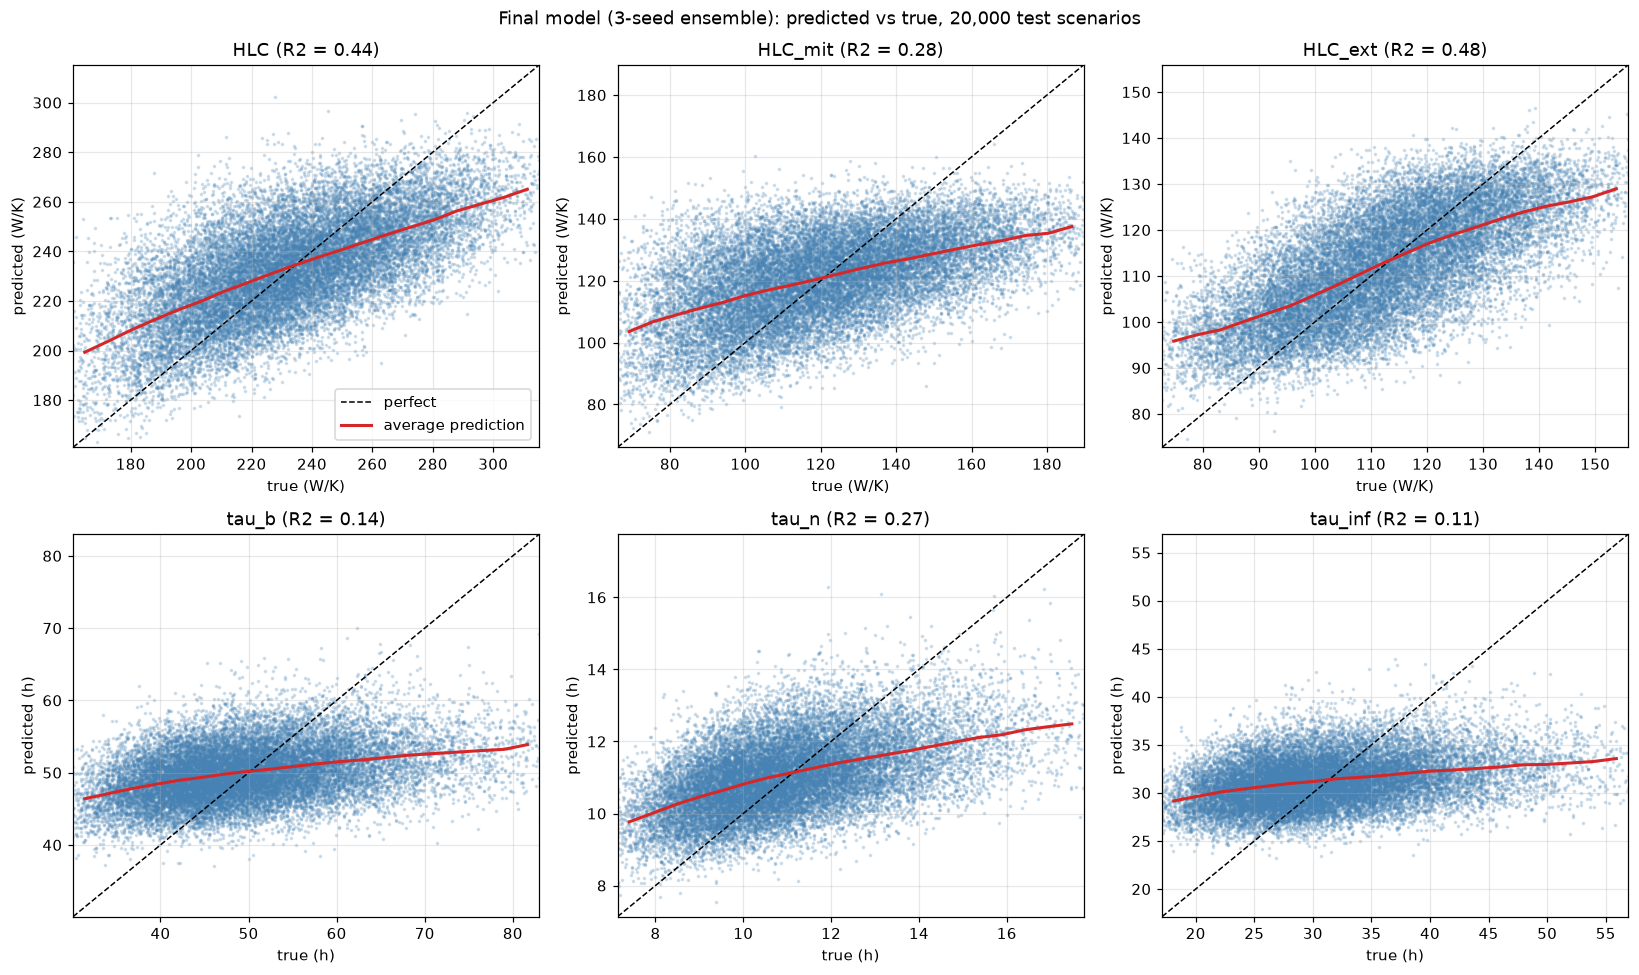

,slope,R2
HLC,0.441,0.440
HLC_mit,0.282,0.282
HLC_ext,0.474,0.476
tau_b,0.144,0.140
tau_n,0.272,0.269
tau_inf,0.113,0.109


In [9]:
display(pd.DataFrame({'final (ensemble)': constraint_violations(pred_final)}))
gap = (pred_final[:, 0] - pred_final[:, 1] - pred_final[:, 2]).abs()
print(f'sum-rule gap: max {gap.max():.2e} W/K (float32 rounding)')

units = ['W/K'] * 3 + ['h'] * 3
sub = torch.randperm(len(test), generator=torch.Generator().manual_seed(SEED))[:20000]
fig, axes = plt.subplots(2, 3, figsize=(15, 9))
slopes = []
for j, (ax, lbl) in enumerate(zip(axes.ravel(), labels)):
    t, p = y_test[:, j], pred_final[:, j]
    ax.scatter(t[sub], p[sub], s=2, alpha=0.2, color='steelblue')
    lo, hi = t.quantile(0.005).item(), t.quantile(0.995).item()
    ax.plot([lo, hi], [lo, hi], 'k--', lw=1, label='perfect')
    edges = torch.linspace(lo, hi, 21)
    centers = (edges[:-1] + edges[1:]) / 2
    ax.plot(centers, [p[(t >= a) & (t < b)].mean().item() for a, b in zip(edges[:-1], edges[1:])],
            color='tab:red', lw=2, label='average prediction')
    ax.set_xlim(lo, hi); ax.set_ylim(lo, hi)
    ax.set_title(f"{lbl} (R2 = {metrics_final.loc[lbl, 'R2']:.2f})")
    ax.set_xlabel(f'true ({units[j]})'); ax.set_ylabel(f'predicted ({units[j]})')
    slopes.append(torch.cov(torch.stack([t, p]))[0, 1].item() / t.var().item())
axes[0, 0].legend()
fig.suptitle('Final model (3-seed ensemble): predicted vs true, 20,000 test scenarios')
fig.tight_layout()
fig.savefig(FIG_DIR / 'final_predicted_vs_true.png', dpi=150)
plt.show()
pd.DataFrame({'slope': slopes, 'R2': metrics_final['R2'].values}, index=labels).round(3)

**Observations (physics rules, predicted vs true)**
- **The ensemble breaks no physics rule:** the sum rule holds to 6e-5 W/K (float32 rounding), every prediction is positive, and tau_n < tau_inf < tau_b everywhere. Averaging physics-head models keeps all these properties, as expected.
- **Predictions are still pulled toward the mean**, and the slope of the average prediction against the truth is again almost equal to R² (HLC: 0.441 against 0.440; tau_b: 0.144 against 0.140). The model is uncertain but not biased: when the inputs do not pin down the answer, it predicts a value closer to the average.

## 6. Errors by subset and by heating protocol

First the EDA subsets (hot, high HLC, constant heating) on the test split. Then the error is mapped against the settings that generated each heating signal (section 6.1).

In [10]:
temp_max = (test.x[:, 0] * scalers.temp_std + scalers.temp_mean).max(dim=1).values
subsets = {
    'overall': torch.ones(len(test), dtype=torch.bool),
    'hot (> 45 degC)': temp_max > 45.0,
    'high HLC (> 300 W/K)': y_test[:, 0] > 300.0,
    'constant heating': test.x[:, 1].std(dim=1) == 0,
}
rows = []
for name, mask in subsets.items():
    m = per_target_metrics(pred_final[mask], y_test[mask], labels)
    rows.append({'subset': name, 'n': int(mask.sum()), **{f'MAE {l}': m.loc[l, 'MAE'] for l in labels}})
pd.DataFrame(rows).set_index('subset').round(2)

,n,MAE HLC,MAE HLC_mit,MAE HLC_ext,MAE tau_b,MAE tau_n,MAE tau_inf
subset,,,,,,,
overall,150000,18.730000,17.889999,9.90,7.38,1.35,5.58
hot (> 45 degC),119,10.850000,10.090000,7.96,7.84,0.94,5.11
high HLC (> 300 W/K),2808,46.240002,37.709999,12.21,11.36,2.58,8.76
constant heating,13978,20.790001,18.840000,9.70,7.11,1.36,5.43


**Observations (subsets)**
- **The subsets behave as in the first iteration.** High-HLC scenarios have an HLC MAE of 46.2 W/K (the pull toward the mean); constant heating 20.8 W/K, only slightly worse than overall; the 119 hot scenarios are too few to conclude.

### 6.1 Which heating protocol gives the best predictions?

`3_improvements.ipynb` (section 9) showed that the error depends on the number of heater switches. But the number of switches is a *result*. What coEnergy actually chooses on site are the settings of the PRBS generator, stored in the `solicitation` table:
- **minimum duration of an on/off block** (`prbs_min_duration_hours`, 0 to 2 h). The maximum duration is always exactly twice the minimum (checked below), so it is not a separate setting.
- **probability of being on** (`prbs_probability_on`, 0.2 to 0.9).

The heater power (7000 W) and all the other settings are the same in every scenario. So there are only **two free settings**, and they were sampled independently of the building.

This is the same idea as Phase 1 of the reference paper: train the model on (T, U) only, then link each prediction error to the settings of the excitation that produced it, and pick the settings with the lowest error. **The `solicitation` table is used here for analysis only, it is never a model input.**

Protocol for this analysis:
- The map is computed on the **validation** split, and the best settings are **chosen there**.
- The test split is only used to **confirm** the chosen settings, the same way the model itself was chosen on validation and checked once on test.
- Metrics for HLC: RMSE and P95 absolute error, the two metrics used in the paper. R² for HLC_ext and tau_b shows the effect on the other families.

In [11]:
sol = load_solicitation(DATA_DIR)  # generator settings, row i = scenario i (analysis only)
MIN_DUR, P_ON = 'prbs_min_duration_hours', 'prbs_probability_on'
print('max duration = 2 x min duration in every scenario:',
      bool(((sol['prbs_max_duration_hours'] - 2 * sol[MIN_DUR]).abs() < 1e-3).all()))

sol_val = sol.iloc[val.idx.numpy()].reset_index(drop=True)
sol_test = sol.iloc[test.idx.numpy()].reset_index(drop=True)
pred_val_final = val_preds['ensemble (3 seeds)']
switches_val = heating_pattern(val.x[:, 1])['switches']

DUR_BINS = np.arange(0, 2.01, 0.25)              # hours
PON_BINS = np.round(np.arange(0.2, 0.91, 0.1), 2)


def by_setting(col, bins):
    # Validation metrics of the final model, grouped by one generator setting
    groups = pd.cut(sol_val[col], bins=bins, include_lowest=True)
    m = metrics_by_group(pred_val_final, y_val, labels, groups)
    hlc = m.xs('HLC', level='target')
    table = pd.DataFrame({
        'n': hlc['n'],
        'mean switches': switches_val.groupby(groups, observed=False).mean(),
        'constant heating %': 100 * (switches_val == 0).groupby(groups, observed=False).mean(),
        'HLC RMSE': hlc['RMSE'],
        'HLC P95': hlc['P95_abs'],
        **{f'R2 {l}': m.xs(l, level='target')['R2'] for l in ['HLC', 'HLC_ext', 'tau_b']},
    })
    table.index.name = col
    return table.round(3)


display(by_setting(MIN_DUR, DUR_BINS))
display(by_setting(P_ON, PON_BINS))

max duration = 2 x min duration in every scenario: True


,n,mean switches,constant heating %,HLC RMSE,HLC P95,R2 HLC,R2 HLC_ext,R2 tau_b
prbs_min_duration_hours,,,,,,,,
"(-0.001, 0.25]",18811,36.739,0.000,24.275000,47.714001,0.402,0.310,0.066
"(0.25, 0.5]",18804,4.042,2.164,23.600000,46.358002,0.433,0.450,0.134
"(0.5, 0.75]",18441,2.487,8.134,23.944000,46.901001,0.419,0.475,0.149
"(0.75, 1.0]",18781,1.896,7.838,23.495001,46.376999,0.441,0.477,0.144
"(1.0, 1.25]",18735,1.743,8.364,23.143999,45.351002,0.447,0.511,0.139
"(1.25, 1.5]",18797,1.220,9.831,23.171000,45.355000,0.458,0.520,0.145
"(1.5, 1.75]",18733,0.842,17.723,22.806000,44.830002,0.470,0.535,0.166
"(1.75, 2.0]",18898,0.820,19.738,23.101999,45.793999,0.457,0.528,0.174


,n,mean switches,constant heating %,HLC RMSE,HLC P95,R2 HLC,R2 HLC_ext,R2 tau_b
prbs_probability_on,,,,,,,,
"(0.199, 0.3]",21333,4.939,49.487,25.107000,49.451000,0.350,0.492,0.181
"(0.3, 0.4]",21312,6.481,9.239,24.107000,47.375000,0.411,0.482,0.164
"(0.4, 0.5]",21793,7.157,0.000,23.072001,45.597000,0.456,0.469,0.126
"(0.5, 0.6]",21405,7.093,0.000,22.927000,44.738998,0.463,0.473,0.133
"(0.6, 0.7]",21424,6.565,0.000,23.003000,45.393002,0.463,0.481,0.129
"(0.7, 0.8]",21573,6.278,0.000,22.792999,44.412998,0.471,0.464,0.123
"(0.8, 0.9]",21160,5.105,6.229,23.031000,45.083000,0.469,0.469,0.122


scenarios per cell (validation): 2553 to 2828


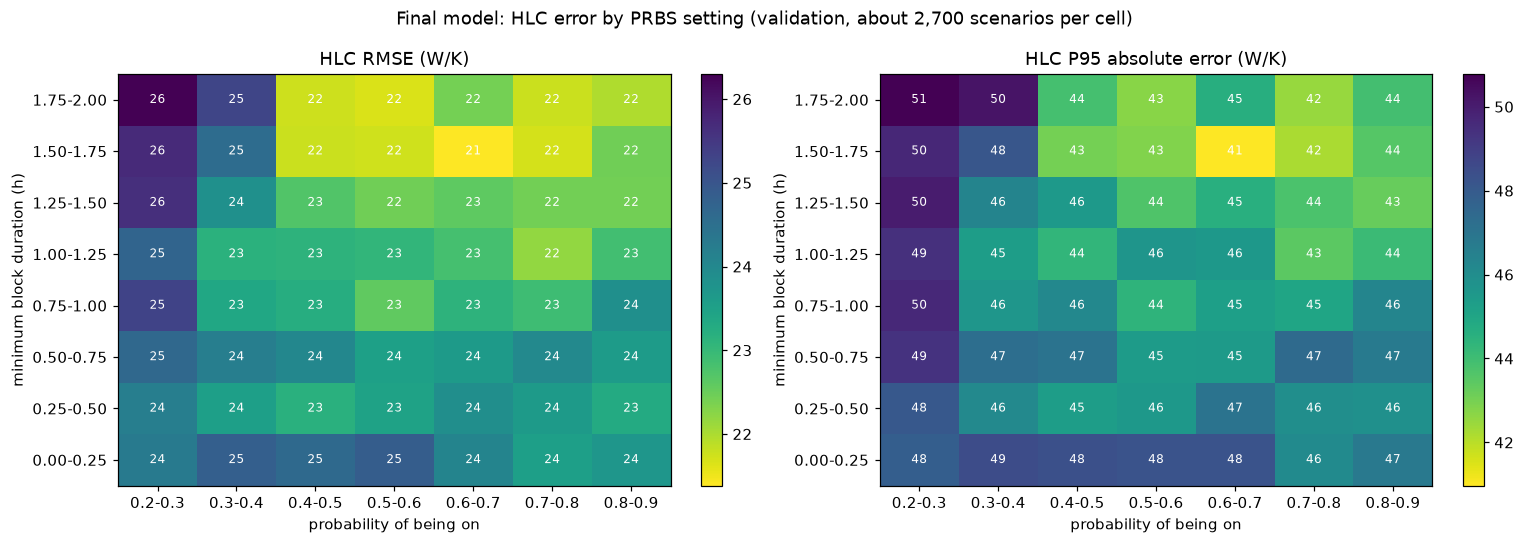

In [12]:
def hlc_error_map(sol_split, pred, y):
    # HLC RMSE, P95 and count for each (minimum duration, probability on) cell
    df = pd.DataFrame({
        'min duration (h)': pd.cut(sol_split[MIN_DUR], DUR_BINS, include_lowest=True),
        'probability on': pd.cut(sol_split[P_ON], PON_BINS, include_lowest=True),
        'err': (pred[:, 0] - y[:, 0]).numpy(),
    })
    g = df.groupby(['min duration (h)', 'probability on'], observed=False)['err']
    rmse = g.apply(lambda e: np.sqrt((e ** 2).mean())).unstack()
    p95 = g.apply(lambda e: e.abs().quantile(0.95)).unstack()
    return rmse, p95, g.size().unstack()


rmse_val, p95_val, n_val = hlc_error_map(sol_val, pred_val_final, y_val)
print(f'scenarios per cell (validation): {n_val.values.min()} to {n_val.values.max()}')

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for ax, (title, table) in zip(axes, [('HLC RMSE (W/K)', rmse_val), ('HLC P95 absolute error (W/K)', p95_val)]):
    im = ax.imshow(table.values, cmap='viridis_r', aspect='auto', origin='lower')
    for i in range(table.shape[0]):
        for j in range(table.shape[1]):
            ax.text(j, i, f'{table.values[i, j]:.0f}', ha='center', va='center', fontsize=8, color='white')
    ax.set_xticks(range(table.shape[1]), [f'{iv.left:.1f}-{iv.right:.1f}' for iv in table.columns])
    ax.set_yticks(range(table.shape[0]), [f'{max(iv.left, 0):.2f}-{iv.right:.2f}' for iv in table.index])
    ax.set_xlabel('probability of being on'); ax.set_ylabel('minimum block duration (h)')
    ax.set_title(title); ax.grid(False)
    fig.colorbar(im, ax=ax, fraction=0.046)
fig.suptitle('Final model: HLC error by PRBS setting (validation, about 2,700 scenarios per cell)')
fig.tight_layout()
fig.savefig(FIG_DIR / 'prbs_error_map.png', dpi=150)
plt.show()

In [13]:
# Settings chosen on validation (lowest HLC RMSE), then checked once on the test split
best = rmse_val.stack().idxmin()
worst = rmse_val.stack().idxmax()
print(f'best cell on validation:  min duration {best[0]} h, probability on {best[1]}')
print(f'worst cell on validation: min duration {worst[0]} h, probability on {worst[1]}')

dur_test = pd.cut(sol_test[MIN_DUR], DUR_BINS, include_lowest=True)
pon_test = pd.cut(sol_test[P_ON], PON_BINS, include_lowest=True)
regions = {
    'all test scenarios': np.ones(len(test), dtype=bool),
    'best settings (chosen on val)': ((dur_test == best[0]) & (pon_test == best[1])).to_numpy(),
    'worst settings (from val)': ((dur_test == worst[0]) & (pon_test == worst[1])).to_numpy(),
}
rows = []
for name, mask in regions.items():
    mask = torch.from_numpy(mask.copy())
    m = per_target_metrics(pred_final[mask], y_test[mask], labels)
    rows.append({'region': name, 'n': int(mask.sum()), 'HLC RMSE': m.loc['HLC', 'RMSE'], 'HLC P95': m.loc['HLC', 'P95_abs'],
                 **{f'R2 {l}': m.loc[l, 'R2'] for l in ['HLC', 'HLC_ext', 'tau_n', 'tau_b']}})
protocol_test = pd.DataFrame(rows).set_index('region')
protocol_test.to_csv(RESULTS_DIR / 'protocol_test.csv')
protocol_test.round(3)

best cell on validation:  min duration (1.5, 1.75] h, probability on (0.6, 0.7]
worst cell on validation: min duration (1.75, 2.0] h, probability on (0.199, 0.3]


,n,HLC RMSE,HLC P95,R2 HLC,R2 HLC_ext,R2 tau_n,R2 tau_b
region,,,,,,,
all test scenarios,150000,23.468000,46.030998,0.440,0.476,0.269,0.140
best settings (chosen on val),2622,22.677999,44.442001,0.468,0.535,0.309,0.153
worst settings (from val),2662,26.316000,51.537998,0.297,0.507,0.216,0.185


**Observations (heating protocol)**
- **Longer blocks give better HLC predictions.** With a minimum block duration of 0.25 h or less, the heater switches about 37 times in 8 hours and HLC R² is 0.40 (HLC_ext 0.31). With blocks of 1.5 to 1.75 h (about 1 switch), HLC R² reaches 0.47 (HLC_ext 0.54). This is the same result as the switches analysis in `3_improvements.ipynb`, now expressed in the setting that we can actually control. Above 1.75 h it gets slightly worse again (0.46), because 20% of these scenarios never switch: the 8-hour window ends before the first block is over.
- **A low probability of being on is the worst setting.** Between 0.2 and 0.3, half of the scenarios (49%) are never heated, and HLC R² drops to 0.35 (RMSE 25.1 W/K). From 0.4 upwards the probability barely matters (RMSE 22.8 to 23.1 W/K).
- **The map combines both effects.** The best area is long blocks with a probability of 0.4 or more (top right: HLC RMSE 21 to 22 W/K, P95 41 to 45 W/K). The worst area is long blocks with a low probability (top left: RMSE 26 W/K, P95 50 to 51 W/K), where the heater is often never switched on.
- **Test confirmation.** The best cell chosen on validation (minimum duration 1.5 to 1.75 h, probability 0.6 to 0.7) also does better on the test split: HLC RMSE 22.7 W/K against 23.5 W/K overall, P95 44.4 against 46.0 W/K, R² 0.47 against 0.44. The worst cell gives RMSE 26.3 W/K and P95 51.5 W/K. On validation the best cell looked a little better (about 21 W/K) than on test: picking the lowest of 56 cells always picks some luck as well. So the recommendation should be the **area**, not the exact cell.
- **There is a trade-off between targets.** The settings that are best for HLC are not best for tau_b: the worst HLC cell has a clearly higher tau_b R² (0.19 on test, against 0.14 overall), because a building left without heating shows its slow free cooling. One protocol cannot be optimal for all six indicators.
- **The protocol helps, but it cannot remove the ceiling.** From the worst to the best settings, the HLC RMSE goes from about 26 to 22 W/K. That is a real gain (about 15%), but far from the 2 W/K reached in the reference paper. The paper's on-site model is trained for a single excitation with the measured boundary conditions, which this dataset does not provide.

**Recommendation for this building and an 8-hour test:** a PRBS with a minimum block duration of about 1.25 to 1.75 h (so blocks of up to 2.5 to 3.5 h) and a probability of being on between 0.4 and 0.8. Avoid very short blocks (under 15 minutes) and a low probability of being on (under 0.3). This is a simple grid version of the paper's Phase 1 (which uses a k-nearest-neighbours error estimate and Bayesian optimization), applied to the same two settings.

## 7. Summary

**Final model:** an ensemble of 3 CNN-GRU models (seeds 0, 1, 2) with a physics-constrained head, trained on the 700k training scenarios for 20 epochs. Input: T_int(t) and U(t) only; dT/dt and the cumulative energy are computed inside the model. The prediction is the average of the three models.

**Test results by indicator family** (150,000 scenarios, test split used once)

| Family | Target | R² | MAE | rel. MAE | P95 abs. error | Family check |
|---|---|---|---|---|---|---|
| **HLC** | HLC | 0.440 | 18.7 W/K | 8.2% | 46.0 W/K | positive in 100% of scenarios |
| **Hb** | HLC_ext | 0.476 | 9.9 W/K | 9.1% | 24.1 W/K | HLC = HLC_mit + HLC_ext: max gap 6e-5 W/K |
| | HLC_mit | 0.282 | 17.9 W/K | 15.7% | 43.5 W/K | |
| **CDT** | tau_n | 0.269 | 1.35 h | 12.4% | 3.3 h | tau_n < tau_inf < tau_b: 0 violations |
| | tau_inf | 0.109 | 5.6 h | 18.5% | 13.7 h | |
| | tau_b | 0.140 | 7.4 h | 15.1% | 18.1 h | |

- **HLC:** moderate. The typical error is 8% of the true value, against 11% for the mean predictor.
- **Hb:** the outside part (HLC_ext) is the best-predicted target overall, the neighbour part (HLC_mit) is much harder. Most of the HLC error comes from HLC_mit.
- **CDT:** tau_n is learned a little; tau_b and tau_inf (tens of hours) are only slightly better than the mean, which makes sense for an 8-hour window.

**What this last step showed**
1. **Ensembling gave the gain, not the extra channel.** The cumulative-energy channel helped on a small subset but not on the full data. A result measured on a subset with short training does not always carry over to the full setting.
2. **The results are very stable:** the 3 seeds differ by at most 0.001 in test R², so the conclusions do not depend on luck.
3. **The physics rules hold exactly** for the final ensemble.
4. **The model is close to the limit of these inputs.** From the baseline CNN to the final model, HLC R² went from 0.37 to 0.44, and the last step only added 0.004.
5. **The heating protocol matters as much as the model.** On the test split, HLC R² is 0.30 with the worst PRBS settings and 0.47 with the best ones (chosen on validation): long blocks (minimum about 1.5 h) and a probability of being on of 0.4 or more.

## 8. Project conclusion

**The task:** 

Predict six indicators of a building (HLC, its split into HLC_ext and HLC_mit, and three time constants) from 8 hours of indoor temperature and heating power, using 1,000,000 simulations of `quentin_house`.

**My work:**
1. **`1_eda.ipynb`:** checked the data and the physics. The sum rule and the order tau_n < tau_inf < tau_b hold in every scenario. Heating is on/off at 7000 W, with only 2,798 distinct schedules, and 9.3% of scenarios never switch. A nearest-neighbour test showed that almost identical input curves can have very different targets, so a perfect model is not possible with these inputs.
2. **`2_modeling.ipynb`:** compared a mean predictor, a simple CNN and a CNN-GRU with a dT/dt channel. The CNN-GRU was clearly better (HLC R² 0.37 -> 0.44, HLC_ext 0.25 -> 0.47). A physics head that builds in the sum rule and the tau order costs no accuracy, so I kept it.
3. **`3_improvements.ipynb`:** small controlled experiments (200k scenarios, 3 seeds each) to see what limits the model. A bigger model, extra channels and other losses all gave little or nothing. More data helped a bit. The heating pattern mattered most.
4. **`4_final_model.ipynb`**: full training with 3 seeds and their average as the final model, evaluated once on the test set. Then a map of the error against the PRBS settings, to find which heating protocol gives the most accurate predictions.

**Main results**
- Test R²: 0.44 for HLC (MAE 18.7 W/K), 0.48 for HLC_ext, 0.28 for HLC_mit, 0.27 for tau_n, 0.14 for tau_b and 0.11 for tau_inf. The physics rules are always respected.
- Predictions are pulled toward the mean (slope of predicted vs true ≈ R²). Buildings far from the average get the largest errors, for example 46 W/K on HLC above 300 W/K.
- With the best PRBS settings, HLC RMSE drops from 23.5 to 22.7 W/K and R² rises from 0.44 to 0.47; with the worst settings, RMSE is 26.3 W/K and R² 0.30.

**Insights**
- **The data limits the result more than the model does.** Three rounds of model changes moved HLC R² by about 0.07 in total, while the choice of heating protocol moves it by about 0.17. The ceiling comes from what 8 hours of indoor temperature and heating power can show about a building.
- **Physics constraints are free here.** Building the sum rule and the tau order into the output layer did not cost accuracy, and it guarantees physically valid predictions on new data.
- **Small experiments need care.** The energy channel looked useful on 200k scenarios but not on 700k. Running 3 seeds per variant is what made it possible to tell real changes from noise.

**Limitations**
- The test set contains the same heating schedules as training (2,798 schedules shared by 1M scenarios), so the score measures "new building, known schedule". A split by schedule was planned but not done.
- All data is simulated, and the temperature has **no measurement noise** (only the 0.01 °C rounding, which is about 100 times smaller than the error of a real sensor). The reference paper adds Gaussian noise calibrated on its sensors during training (indoor sensors rated ±0.25 °C). This model was trained on clean data, and the rounding experiment showed that it uses temperature differences below 0.01 °C, which real sensors cannot resolve. Its accuracy on real measurements would therefore be lower. Training with realistic noise would be the first step before any use on site.
- The training settings are standard values and were not tuned. The training curves and the seed spread show no problem, but a small gain from tuning cannot be ruled out.
- The ensemble costs 3× the training time and 3× the prediction time for a gain of about 0.004 in R².

**Recommendations**

The results suggest that the measurement protocol matters more than the model:
- **Choose the PRBS settings with the error map:** for this building and an 8-hour test, a minimum block duration of about 1.25 to 1.75 h and a probability of being on between 0.4 and 0.8. Very short blocks and a low probability of being on should be avoided. This is the same idea as the reference paper's excitation optimization.
- **Measure the outdoor and neighbouring temperatures** if possible. Without them, separating HLC_ext from HLC_mit is hard.
- **Longer measurement windows** would help the long time constants (tau_b ≈ 50 h cannot be seen well in 8 h).
- **Keep the full sensor resolution:** removing the 0.01 °C rounding gave a small but real gain in the experiments.